In [1]:
import pandas as pd
import holidays

def load_daily_exits(path):
    df = pd.read_csv(
        path,
        names=["date", "hour", "origin", "dest", "trips"],
        usecols=["date", "dest", "trips"],          # skip columns we don't need
        dtype={"dest": "category", "trips": "int32"},
    )
    return df.groupby(["date", "dest"], observed=True)["trips"].sum().reset_index()

daily = pd.concat([
    load_daily_exits("../data/raw/date-hour-soo-dest-2024.csv.gz"),
    load_daily_exits("../data/raw/date-hour-soo-dest-2025.csv.gz"),
])
daily = daily.rename(columns={"dest": "station", "trips": "exits"})
daily["date"] = pd.to_datetime(daily["date"])
daily.head()

,date,station,exits
0,2024-01-01,12TH,1181
1,2024-01-01,16TH,1994
2,2024-01-01,19TH,1291
3,2024-01-01,24TH,1877
4,2024-01-01,ANTC,347


In [2]:
top = daily.groupby("station", observed=True)["exits"].sum().nlargest(8).index
daily = daily[daily["station"].isin(top)].copy()
daily["station"] = daily["station"].astype(str)
print(list(top))

['EMBR', 'MONT', 'POWL', 'CIVC', 'DBRK', '16TH', '24TH', '12TH']


In [3]:
weather = pd.read_csv("../data/raw/weather.csv", parse_dates=["date"])
df = daily.merge(weather, on="date", how="left")
df.isna().sum()   # should be all zeros

date          0
station       0
exits         0
temp_max_f    0
precip_in     0
dtype: int64

In [4]:
us_holidays = holidays.US(years=[2024, 2025])

df["day_of_week"] = df["date"].dt.day_name()
df["month"] = df["date"].dt.month
df["is_holiday"] = df["date"].dt.date.isin(us_holidays).astype(int)

df.sample(10)

,date,station,exits,temp_max_f,precip_in,day_of_week,month,is_holiday
4425,2025-07-07,16TH,5078,69.2,0.000,Monday,7,0
323,2024-02-10,CIVC,5857,62.0,0.000,Saturday,2,0
2265,2024-10-10,16TH,5711,73.1,0.000,Thursday,10,0
789,2024-04-08,EMBR,14443,71.2,0.000,Monday,4,0
1195,2024-05-29,CIVC,9346,80.8,0.000,Wednesday,5,0
1634,2024-07-23,24TH,5283,86.4,0.000,Tuesday,7,0
2868,2024-12-24,DBRK,1548,59.5,0.547,Tuesday,12,0
336,2024-02-12,12TH,4141,60.7,0.000,Monday,2,0
5500,2025-11-18,DBRK,6685,61.0,0.004,Tuesday,11,0
3112,2025-01-24,12TH,4559,61.7,0.000,Friday,1,0


In [5]:
df.to_csv("../data/processed/bart_daily.csv", index=False)
print(df.shape)

(5848, 8)


In [6]:
import sys
sys.path.append("../src")

import pandas as pd
from linreg.preprocessing import *

df = pd.read_csv("../data/processed/bart_daily.csv")
train, test = split_by_date(df)

print(train['date'].max(), test['date'].min())
print(len(train) + len(test) == len(df))


2024-12-31 00:00:00 2025-01-01 00:00:00
True


In [7]:
categories = fit_one_hot(train)
train_enc = transform_one_hot(train, categories)
test_enc = transform_one_hot(test, categories)

print(list(train_enc.columns.tolist()))
print(train[["day_of_week", "month", "station"]].nunique())
print(list(train_enc.columns) == list(test_enc.columns))
print(train_enc.shape[1])



['date', 'exits', 'temp_max_f', 'precip_in', 'is_holiday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'station_16TH', 'station_24TH', 'station_CIVC', 'station_DBRK', 'station_EMBR', 'station_MONT', 'station_POWL']
day_of_week     7
month          12
station         8
dtype: int64
True
29


In [9]:
stats = fit_scaler(train_enc)
train_ready = transform_scaler(train_enc, stats)
test_ready = transform_scaler(test_enc, stats)

print(stats)
print(train_ready[NUMERICAL_COLS].agg(['mean', 'std']))
print(test_ready[NUMERICAL_COLS].agg(['mean', 'std']))

{'temp_max_f': (np.float64(69.18907103825137), np.float64(10.787827515555302)), 'precip_in': (np.float64(0.08566120218579235), np.float64(0.2460363534657144))}
        temp_max_f     precip_in
mean -3.882747e-16  4.853434e-17
std   1.000000e+00  1.000000e+00
      temp_max_f  precip_in
mean   -0.187886  -0.094934
std     0.792762   0.883323


In [18]:
df = pd.read_csv("../data/processed/bart_daily.csv", parse_dates=['date'])

# Checks before moving on

print(df.isna().sum())
print(df.duplicated(subset=['date', 'station']).sum())
print(df['date'].max())
print(df['date'].min())
print(df['date'].nunique())
print(df['station'].value_counts())


date           0
station        0
exits          0
temp_max_f     0
precip_in      0
day_of_week    0
month          0
is_holiday     0
dtype: int64
0
2025-12-31 00:00:00
2024-01-01 00:00:00
731
station
12TH    731
16TH    731
24TH    731
CIVC    731
DBRK    731
EMBR    731
MONT    731
POWL    731
Name: count, dtype: int64


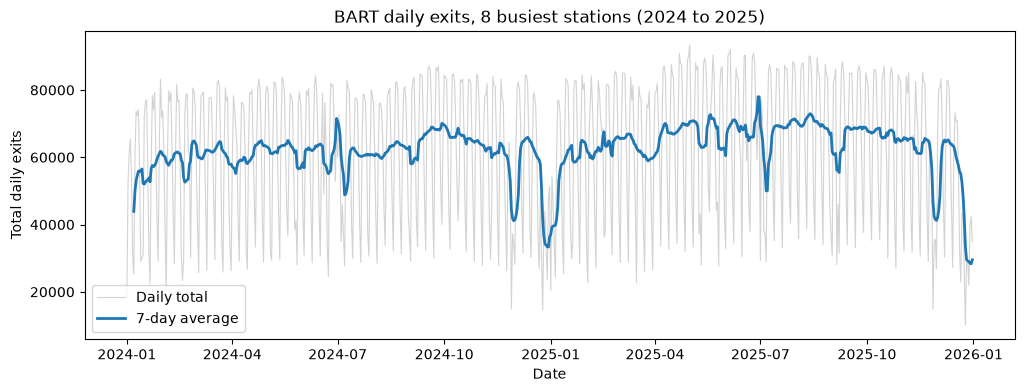

In [27]:
import matplotlib.pyplot as plt

daily_total = df.groupby("date")["exits"].sum()
rolling_avg = daily_total.rolling(7).mean()

plt.figure(figsize=(12, 4))
plt.plot(daily_total, color="lightgray", linewidth=0.8, label="Daily total")
plt.plot(rolling_avg, color="tab:blue", linewidth=2, label="7-day average")

plt.xlabel("Date")
plt.ylabel("Total daily exits")
plt.title("BART daily exits, 8 busiest stations (2024 to 2025)")
plt.legend()

plt.savefig("../figures/ridership_over_time.png", dpi=150, bbox_inches="tight")
plt.show()
